# Demo — Role 2: DeBERTa, local context and the decision threshold
**Group 06 · CLC02 · Role 2**

Everything below is computed from the **saved outputs of the final project** (`MLA_Final/`): no model is re-trained and the official test labels are only read from saved prediction files.

**Run all cells top to bottom (Run All).** The raw PERSUADE train CSV is optional: it is only needed to print the neighbouring units of case 8.

Steps: ① reproduce Table 2 (L1 − L0) → ② case 8 at Level 0 and Level 1 → ③ move the Ineffective threshold θ → ④ is case 8 flagged?

## 0 · Setup

In [1]:
import sys, hashlib, textwrap
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
from sklearn.metrics import f1_score

# find the repo root from wherever the notebook is opened
HERE = Path.cwd()
ROOT = next(p for p in [HERE, *HERE.parents] if (p / "MLA_Final").is_dir())
sys.path.insert(0, str(ROOT / "VIDEO_CA_NHAN" / "build"))
sys.dont_write_bytecode = True
import make_visuals as data          # shared loaders: same numbers as the slides

pd.set_option("display.width", 140, "display.max_colwidth", 120)
LABELS = data.LABELS                  # Ineffective=0, Adequate=1, Effective=2

from IPython.display import HTML
def show(df, fmt=None, index=False):
    """Big, readable HTML table (no jinja2 needed)."""
    df = df.copy()
    for col, f in (fmt or {}).items():
        df[col] = df[col].map(lambda v, f=f: f.format(v) if isinstance(v, (int, float, np.number)) else v)
    display(HTML('<div style="font-size:18px; line-height:1.5">' + df.to_html(index=index) + "</div>"))

print("repo root:", ROOT)

repo root: C:\Users\Admin\Desktop\MLA


## ① Reproduce the paper's tables
Look at **TABLE 2: Level 1 minus Level 0 on the same units**.

In [2]:
import subprocess
out = subprocess.run([sys.executable, "reproduce_results.py"], cwd=ROOT / "MLA_Final" / "Code",
                     capture_output=True, text=True, encoding="utf-8")
print(out.stdout[-2200:])

-----------------------------------------------------------------------------
Test   | Majority (Adequate)        | 0.297    | 0.000    |   0.0%   | 0.892   | 0.000   |  80.4%
Test   | Random Forest (FS-B)       | 0.510    | 0.202    |  17.2%   | 0.870   | 0.457   |  78.5%
Test   | DeBERTa-v3 L0 (unit only)  | 0.561    | 0.339    |  37.2%   | 0.831   | 0.514   |  74.4%
Test   | DeBERTa-v3 L1 (locked)     | 0.577    | 0.368    |  41.5%   | 0.841   | 0.523   |  75.7%
Test   | DeBERTa-v3 Prompt-Aware    | 0.581    | 0.379    |  44.2%   | 0.838   | 0.526   |  75.4%

TABLE 2: Level 1 minus Level 0 on the Same Units (RQ2)
Metric                    | Validation (29,102 units)  | Official Test (93,677 units)
-----------------------------------------------------------------------------------
Macro-F1 delta            | +0.0087 (paper: +0.0087)       | +0.0159 (paper: +0.0159)
F1 Ineffective delta      | +0.0091 (paper: +0.0091)       | +0.0292 (paper: +0.0292)
F1 Adequate delta         | +0.010

## ② Case 8: what DeBERTa reads at Level 0 and Level 1
Validation `row_idx` 108,613 — a Claim on *Cell phones at school*, gold **Ineffective**.

In [3]:
USE_RAW = data.raw_path("train").exists()
raw_train = data.raw_optional("train", no_raw=not USE_RAW)
e, l0_input, l1_input = data.inputs_case8(raw_train)
for name, text in [("Level 0 input", l0_input), ("Level 1 input", l1_input)]:
    print(name + ":")
    print(textwrap.fill(text, 110, initial_indent="   ", subsequent_indent="   "), "\n")
probs = pd.DataFrame({m: [f"{r['pred_proba_' + str(i)]:.3f}" for i in range(3)] + [LABELS[int(r.pred_label)]]
                      for m in ["L0", "L1"] for r in [data.probability_row("val", m, 108613)]},
                     index=["P(Ineffective)", "P(Adequate)", "P(Effective)", "prediction"])
show(probs, index=True)
print("gold label:", LABELS[int(e["label"])])

Level 0 input:
   Claim [SEP] Some kids will ask there parents to transfer school 

Level 1 input:
   Claim [SEP] Previous: They will hide them from the teachers .Teachers can't go threw the students stuff any
   way . Just make the kids put them in there locker during class.  If you do a lot of the students will dich
   school any way, to be on there phones. You will just make all the kids mad. [SEP] Target: Some kids will
   ask there parents to transfer school [SEP] Next: If you chose policy one you will make the student happy. 



,L0,L1
P(Ineffective),0.017,0.058
P(Adequate),0.962,0.937
P(Effective),0.021,0.005
prediction,Adequate,Adequate


gold label: Ineffective


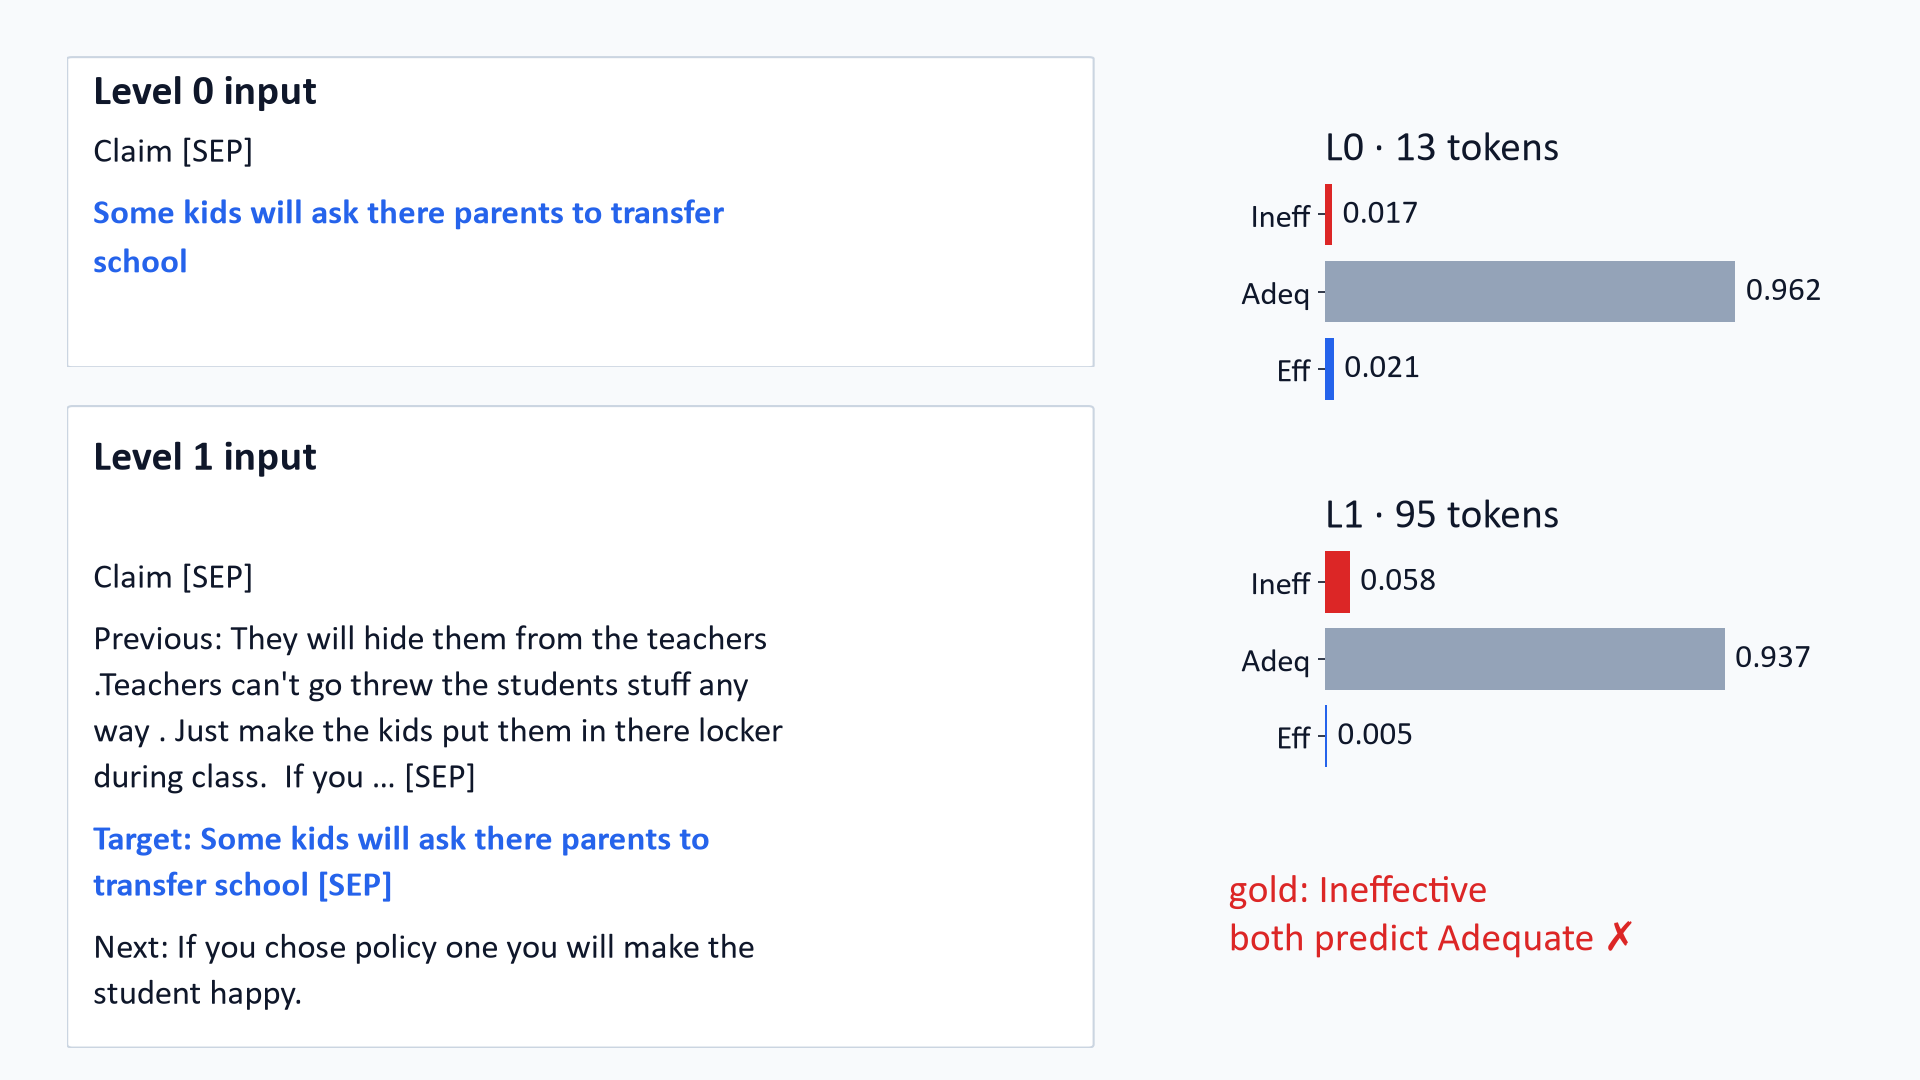

In [4]:
display(Image(filename=str(ROOT / "VIDEO_CA_NHAN/Nguoi_2_DeBERTa_Context_Threshold/visuals/v1_case8_L0_vs_L1.png"), width=1100))

## ③ Flag a unit as Ineffective if P(Ineffective) ≥ θ
Locked L1 model, **validation** only (θ is never chosen on the test). Change `THETA` and re-run this cell to show the trade-off live.

In [5]:
THETA = 0.10

df = data.predictions("val", "L1")
p = df[[f"pred_proba_{i}" for i in range(3)]].to_numpy(); y = df.true_label.to_numpy()
rules = {"argmax": p.argmax(axis=1),
         f"θ = {THETA:.2f}": np.where(p[:, 0] >= THETA, 0, p[:, 1:].argmax(axis=1) + 1)}
rows = []
for name, pred in rules.items():
    flagged = int((pred == 0).sum()); tp = int(((pred == 0) & (y == 0)).sum())
    rows.append((name, flagged, tp / (y == 0).sum(), tp / flagged, f1_score(y, pred, average="macro"), tp, flagged - tp))
t = pd.DataFrame(rows, columns=["rule", "units flagged", "recall Ineff", "precision Ineff", "Macro-F1", "true flags", "false alarms"])
show(t, {"units flagged": "{:,}", "recall Ineff": "{:.1%}", "precision Ineff": "{:.1%}",
         "Macro-F1": "{:.3f}", "true flags": "{:,}", "false alarms": "{:,}"})
extra, false = rows[1][5] - rows[0][5], rows[1][6] - rows[0][6]
print(f"extra correct flags: {extra:,} | extra false alarms: {false:,} | false alarms per extra catch: {false/extra:.1f}")

rule,units flagged,recall Ineff,precision Ineff,Macro-F1,true flags,false alarms
argmax,"1,761",44.7%,33.7%,0.581,594,"1,167"
θ = 0.10,"4,633",69.6%,19.9%,0.535,924,"3,709"


extra correct flags: 330 | extra false alarms: 2,542 | false alarms per extra catch: 7.7


## ④ Is case 8 flagged at this θ?

In [6]:
p8 = data.probability_row("val", "L1", 108613).pred_proba_0
print(f"case 8: P(Ineffective) = {p8:.3f} {'≥' if p8 >= THETA else '<'} θ = {THETA:.2f} -> "
      f"{'flagged' if p8 >= THETA else 'NOT flagged'}")

case 8: P(Ineffective) = 0.058 < θ = 0.10 -> NOT flagged


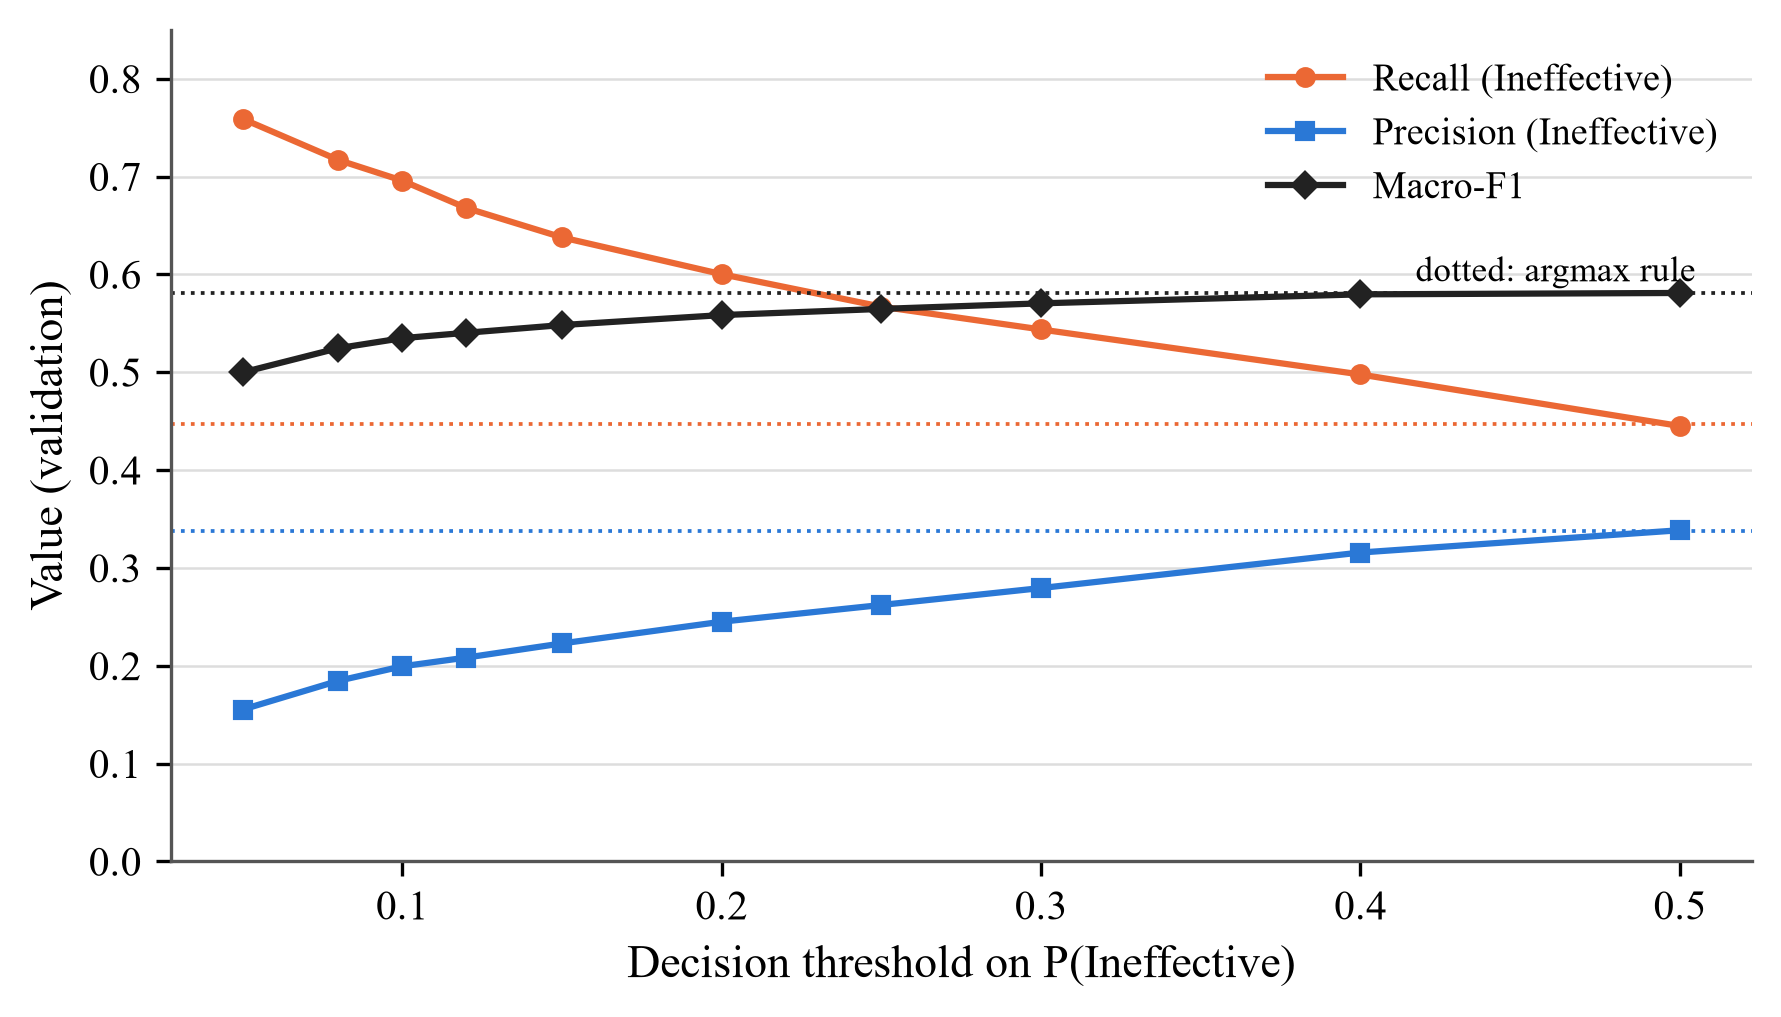

In [7]:
display(Image(filename=str(ROOT / "VIDEO_CA_NHAN/Nguoi_2_DeBERTa_Context_Threshold/visuals/fig22_threshold_tradeoff.png"), width=900))